## Các thư viện

In [1]:
from pathlib import Path
import math

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR

pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True, 'grid.alpha': 0.22, 'font.size': 10})
RANDOM_STATE = 42

print('Đã nhập thư viện thành công.')

Đã nhập thư viện thành công.


## Đường dẫn đồ án

In [2]:
DATA_FILENAME = 'rice_ml_features_2000_2022.csv'
folders = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((folder for folder in folders
    if (folder / 'data' / 'processed' / DATA_FILENAME).is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Không tìm thấy data/processed/rice_ml_features_2000_2022.csv; kiểm tra vị trí notebook và file CSV.')
DATA_FILE = PROJECT_ROOT / 'data' / 'processed' / DATA_FILENAME
REPORTS_DIR = PROJECT_ROOT / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'
MODELS_DIR = PROJECT_ROOT / 'models'
for folder in [REPORTS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    path = FIGURES_DIR / name
    plt.savefig(path, dpi=160, bbox_inches='tight')
    print('Đã lưu:', path)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('CSV:', DATA_FILE)

PROJECT_ROOT: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation
CSV: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\data\processed\rice_ml_features_2000_2022.csv


## Đọc và hiển thị bảng CSV đầu vào
Bảng gồm 24 cột:
- **adm1_code**:            Mã định danh tỉnh theo GAUL 2015.
- **tinh_thanh**:           Tên tỉnh/thành phố.
- **nam**:                  Năm thống kê năng suất lúa.
- **mua_vu**:               Nhóm mùa vụ: dong_xuan hoặc he_thu-thu_dong.
- **nang_suat_t_ha**:	    Năng suất lúa (tấn/ha) — biến mục tiêu cần dự đoán.
- **window_start**:         Tháng bắt đầu khoảng thời gian lấy dữ liệu môi trường.
- **window_end**:           Tháng kết thúc khoảng thời gian lấy dữ liệu môi trường.
- **window_months**:        Tổng số tháng trong khoảng thời gian quan sát.
- **temperature_mean_c**:   Nhiệt độ trung bình trong khoảng quan sát (°C).
- **temperature_min_c**:    Nhiệt độ trung bình tháng thấp nhất trong khoảng quan sát (°C).
- **temperature_max_c**:    Nhiệt độ trung bình tháng cao nhất trong khoảng quan sát (°C).
- **rainfall_sum_mm**:      Tổng lượng mưa trong khoảng quan sát (mm).
- **rainfall_max_month_mm**:Lượng mưa của tháng mưa nhiều nhất (mm).
- **rainy_months_100mm**:   Số tháng có lượng mưa từ 100 mm trở lên.
- **ndvi_mean**:            Giá trị NDVI trung bình trong khoảng quan sát, phản ánh mức độ xanh của thảm thực vật vùng lúa.
- **ndvi_max**:             Giá trị NDVI cao nhất trong khoảng quan sát.
- **evi_mean**:             Giá trị EVI trung bình trong khoảng quan sát, phản ánh tình trạng thảm thực vật và tán lá.
- **evi_max**:              Giá trị EVI cao nhất trong khoảng quan sát.
- **vci_mean**:             Giá trị VCI trung bình trong khoảng quan sát, phản ánh tình trạng thực vật so với mức biến động lịch sử.
- **vci_min**:              Giá trị VCI thấp nhất trong khoảng quan sát.
- **vi_months_available**:  Số tháng có dữ liệu chỉ số thực vật hợp lệ.
- **vi_months_quality80**:  Số tháng có độ phủ pixel vệ tinh đạt ít nhất 80%.
- **vi_quality80_ratio**:   Tỷ lệ số tháng đạt độ phủ ≥80% trên tổng số tháng trong cửa sổ quan sát (0–1).
- **vi_mean_coverage_pct**: Tỷ lệ pixel vệ tinh hợp lệ trung bình của các tháng có dữ liệu (%).

In [3]:
df = pd.read_csv(DATA_FILE, encoding='utf-8-sig')
if df.shape[0] != 579:
    raise ValueError(f'Số dòng bất thường: {df.shape[0]}, dự kiến 579.')
if df.duplicated(subset=['adm1_code', 'nam', 'mua_vu']).any():
    raise ValueError('Trùng tỉnh–năm–nhóm vụ.')
print(f'Dữ liệu đầu vào: {df.shape[0]} dòng × {df.shape[1]} cột')
print('Danh sách cột:', ', '.join(df.columns))
print('\nBẢNG DỮ LIỆU CSV (tổng quan):')
display(df)
print('\n20 DÒNG ĐẦU:')
display(df.head(20))

Dữ liệu đầu vào: 579 dòng × 24 cột
Danh sách cột: adm1_code, tinh_thanh, nam, mua_vu, nang_suat_t_ha, window_start, window_end, window_months, temperature_mean_c, temperature_min_c, temperature_max_c, rainfall_sum_mm, rainfall_max_month_mm, rainy_months_100mm, ndvi_mean, ndvi_max, evi_mean, evi_max, vci_mean, vci_min, vi_months_available, vi_months_quality80, vi_quality80_ratio, vi_mean_coverage_pct

BẢNG DỮ LIỆU CSV (tổng quan):


,adm1_code,tinh_thanh,nam,mua_vu,nang_suat_t_ha,window_start,window_end,window_months,temperature_mean_c,temperature_min_c,temperature_max_c,rainfall_sum_mm,rainfall_max_month_mm,rainy_months_100mm,ndvi_mean,ndvi_max,evi_mean,evi_max,vci_mean,vci_min,vi_months_available,vi_months_quality80,vi_quality80_ratio,vi_mean_coverage_pct
0,3326,An Giang,2000,dong_xuan,6.102087,1999-11,2000-04,6,26.466908,24.330084,27.914765,545.048294,214.227481,3,0.724219,0.744950,0.569938,0.593500,72.977768,71.174059,3,2,0.333333,96.889450
1,3326,An Giang,2000,he_thu-thu_dong,3.466495,2000-04,2000-11,8,26.675126,26.067092,27.584485,1736.698680,509.919381,8,0.591241,0.703487,0.404596,0.546375,53.749824,35.903772,8,6,0.750000,95.912700
2,3330,Bạc Liêu,2000,dong_xuan,4.203488,1999-11,2000-04,6,26.106606,24.316530,27.404704,414.761425,217.156484,1,0.387330,0.388726,0.276310,0.282784,19.819480,13.099415,3,2,0.333333,87.388850
3,3330,Bạc Liêu,2000,he_thu-thu_dong,4.293144,2000-04,2000-11,8,26.545792,25.896140,27.404704,2062.095680,511.461230,7,0.575510,0.714352,0.377099,0.497747,45.226848,26.539546,8,8,1.000000,93.997575
4,3332,Bến Tre,2000,dong_xuan,4.849138,1999-11,2000-04,6,26.128369,24.343505,27.493628,276.675692,165.433183,1,NaN,NaN,NaN,NaN,NaN,NaN,3,0,0.000000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
574,3388,Vĩnh Long,2022,he_thu-thu_dong,5.377273,2022-04,2022-11,8,26.668944,26.004816,27.387426,1713.305245,296.295645,7,0.644718,0.701980,0.411415,0.480254,57.578935,47.617742,8,7,0.875000,92.803343
575,73933,Cần Thơ,2022,dong_xuan,7.421053,2021-11,2022-04,6,26.734543,25.629700,27.914324,414.584406,213.007587,2,0.721098,0.797980,0.540403,0.644392,78.367360,68.429447,6,6,1.000000,99.395600
576,73933,Cần Thơ,2022,he_thu-thu_dong,5.721311,2022-04,2022-11,8,26.750825,26.212127,27.264282,1684.628158,280.710486,8,0.710439,0.743450,0.509580,0.546217,72.417993,56.294576,8,6,0.750000,94.360800
577,73937,Hậu Giang,2022,dong_xuan,7.783290,2021-11,2022-04,6,26.638651,25.586949,27.735058,436.853583,223.810728,2,0.606366,0.756882,0.430857,0.591822,61.185835,43.249419,6,6,1.000000,97.197800



20 DÒNG ĐẦU:


,adm1_code,tinh_thanh,nam,mua_vu,nang_suat_t_ha,window_start,window_end,window_months,temperature_mean_c,temperature_min_c,temperature_max_c,rainfall_sum_mm,rainfall_max_month_mm,rainy_months_100mm,ndvi_mean,ndvi_max,evi_mean,evi_max,vci_mean,vci_min,vi_months_available,vi_months_quality80,vi_quality80_ratio,vi_mean_coverage_pct
0,3326,An Giang,2000,dong_xuan,6.102087,1999-11,2000-04,6,26.466908,24.330084,27.914765,545.048294,214.227481,3,0.724219,0.744950,0.569938,0.593500,72.977768,71.174059,3,2,0.333333,96.889450
1,3326,An Giang,2000,he_thu-thu_dong,3.466495,2000-04,2000-11,8,26.675126,26.067092,27.584485,1736.698680,509.919381,8,0.591241,0.703487,0.404596,0.546375,53.749824,35.903772,8,6,0.750000,95.912700
2,3330,Bạc Liêu,2000,dong_xuan,4.203488,1999-11,2000-04,6,26.106606,24.316530,27.404704,414.761425,217.156484,1,0.387330,0.388726,0.276310,0.282784,19.819480,13.099415,3,2,0.333333,87.388850
3,3330,Bạc Liêu,2000,he_thu-thu_dong,4.293144,2000-04,2000-11,8,26.545792,25.896140,27.404704,2062.095680,511.461230,7,0.575510,0.714352,0.377099,0.497747,45.226848,26.539546,8,8,1.000000,93.997575
4,3332,Bến Tre,2000,dong_xuan,4.849138,1999-11,2000-04,6,26.128369,24.343505,27.493628,276.675692,165.433183,1,NaN,NaN,NaN,NaN,NaN,NaN,3,0,0.000000,NaN
5,3332,Bến Tre,2000,he_thu-thu_dong,3.901695,2000-04,2000-11,8,26.581927,25.853674,27.493628,1631.040919,490.508300,7,0.641513,0.742944,0.427153,0.530938,44.059030,10.698662,8,7,0.875000,96.681100
6,3339,Cà Mau,2000,dong_xuan,3.673333,1999-11,2000-04,6,26.133275,24.374156,27.374585,452.618200,191.914331,1,0.505844,0.517804,0.323351,0.339427,41.888396,24.910899,3,2,0.333333,91.716650
7,3339,Cà Mau,2000,he_thu-thu_dong,4.190255,2000-04,2000-11,8,26.587323,25.888778,27.469344,2164.949332,517.154307,7,0.567894,0.663491,0.315363,0.376903,58.682323,37.543953,8,8,1.000000,96.773700
8,3343,Đồng Tháp,2000,dong_xuan,5.872852,1999-11,2000-04,6,26.616159,24.464337,28.148798,459.503678,195.319909,2,0.771641,0.853655,0.619410,0.705865,83.286998,75.197259,3,3,0.500000,90.507333
9,3343,Đồng Tháp,2000,he_thu-thu_dong,3.332682,2000-04,2000-11,8,26.731731,26.084791,27.825716,1696.132797,488.333965,8,0.636636,0.702755,0.443378,0.536339,57.015825,41.074860,8,5,0.625000,98.489160


## Phân tích thông kê mô tả và dữ liệu thiếu

THỐNG KÊ CÁC CỘT SỐ:


,count,mean,std,min,25%,50%,75%,max
nam,579.0,2011.111,6.634,2000.000,2005.000,2011.000,2017.000,2022.000
temperature_mean_c,579.0,26.940,0.438,25.830,26.634,26.934,27.239,28.178
temperature_min_c,579.0,25.770,0.594,23.957,25.431,25.870,26.203,27.059
temperature_max_c,579.0,28.620,0.860,26.822,27.874,28.572,29.309,30.918
rainfall_sum_mm,579.0,987.837,691.843,93.707,302.196,1179.164,1626.566,2253.406
rainfall_max_month_mm,579.0,246.072,108.797,50.406,156.122,240.450,312.849,551.705
rainy_months_100mm,579.0,4.206,2.979,0.000,1.000,5.000,7.000,8.000
ndvi_mean,578.0,0.603,0.056,0.387,0.563,0.600,0.641,0.780
ndvi_max,578.0,0.716,0.045,0.389,0.693,0.718,0.744,0.854
evi_mean,578.0,0.416,0.057,0.276,0.376,0.416,0.453,0.619


GIÁ TRỊ THIẾU THEO CỘT:


,so_gia_tri_thieu
vi_mean_coverage_pct,1
evi_mean,1
vci_mean,1
vci_min,1
ndvi_max,1
evi_max,1
ndvi_mean,1
adm1_code,0
window_months,0
window_end,0


SỐ BẢN GHI THEO NHÓM VỤ:


,count,mean,std,min,max
mua_vu,,,,,
dong_xuan,284,6.160,1.132,0.038,7.821
he_thu-thu_dong,295,4.775,0.749,2.576,6.317


Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\01_gia_tri_thieu.png


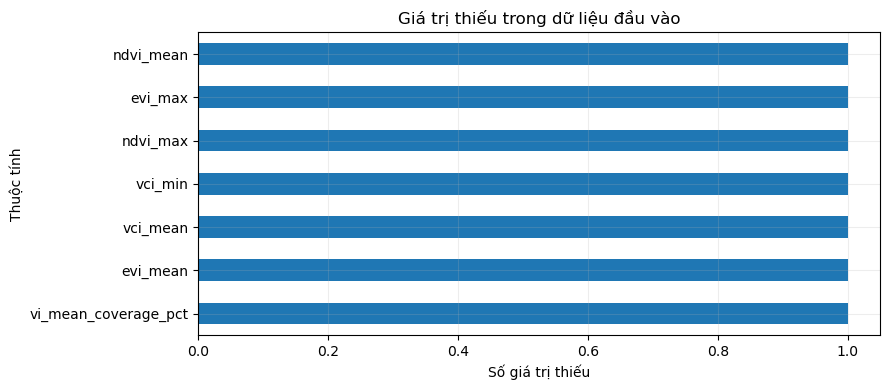

In [4]:
TARGET = 'nang_suat_t_ha'
NUMERIC_FEATURES = [
    'nam', 'temperature_mean_c', 'temperature_min_c', 'temperature_max_c',
    'rainfall_sum_mm', 'rainfall_max_month_mm', 'rainy_months_100mm',
    'ndvi_mean', 'ndvi_max', 'evi_mean', 'evi_max', 'vci_mean', 'vci_min',
    'vi_months_available', 'vi_months_quality80', 'vi_quality80_ratio',
    'vi_mean_coverage_pct',
]
CATEGORICAL_FEATURES = ['adm1_code', 'mua_vu']
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
required = set(FEATURES + [TARGET, 'tinh_thanh'])
if not required.issubset(df.columns):
    raise ValueError(f'Thiếu cột: {sorted(required - set(df.columns))}')

for col in NUMERIC_FEATURES + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors='raise')
df['nam'] = df['nam'].astype(int)
for col in CATEGORICAL_FEATURES:
    df[col] = df[col].astype(str)
if df[TARGET].isna().any():
    raise ValueError('Nhãn năng suất không được thiếu.')

print('THỐNG KÊ CÁC CỘT SỐ:')
display(df[NUMERIC_FEATURES + [TARGET]].describe().T.round(3))
missing = df.isna().sum().sort_values(ascending=False)
print('GIÁ TRỊ THIẾU THEO CỘT:')
display(missing.to_frame('so_gia_tri_thieu'))
print('SỐ BẢN GHI THEO NHÓM VỤ:')
display(df.groupby('mua_vu')[TARGET].agg(['count','mean','std','min','max']).round(3))

if (missing > 0).any():
    fig, ax = plt.subplots(figsize=(9, 4))
    missing[missing > 0].sort_values().plot.barh(ax=ax)
    ax.set(xlabel='Số giá trị thiếu', ylabel='Thuộc tính', title='Giá trị thiếu trong dữ liệu đầu vào')
    plt.tight_layout(); save_fig('01_gia_tri_thieu.png'); plt.show()
else:
    print('Không có giá trị thiếu.')

## Trực quan hóa dữ liệu đầu vào

Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\02_phan_phoi_nang_suat.png


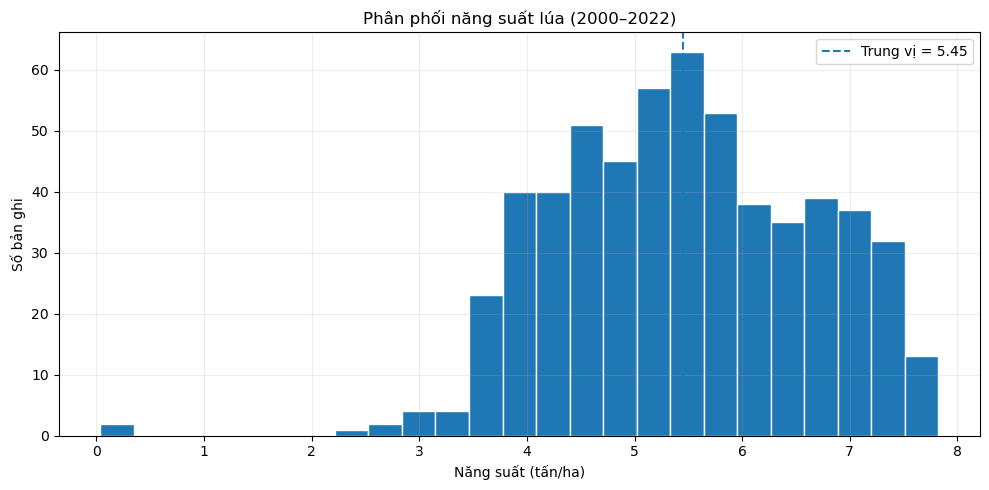

Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\03_nang_suat_theo_nhom_vu.png


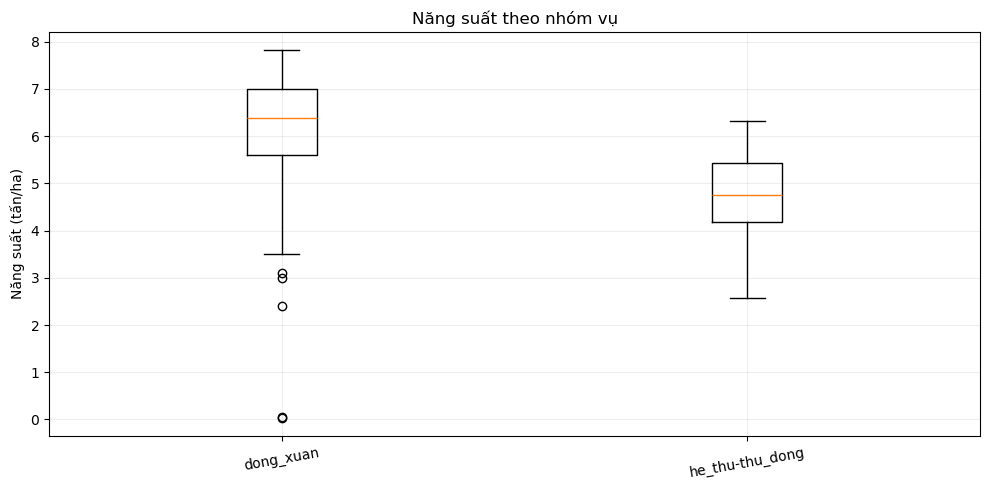

Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\04_xu_huong_nang_suat.png


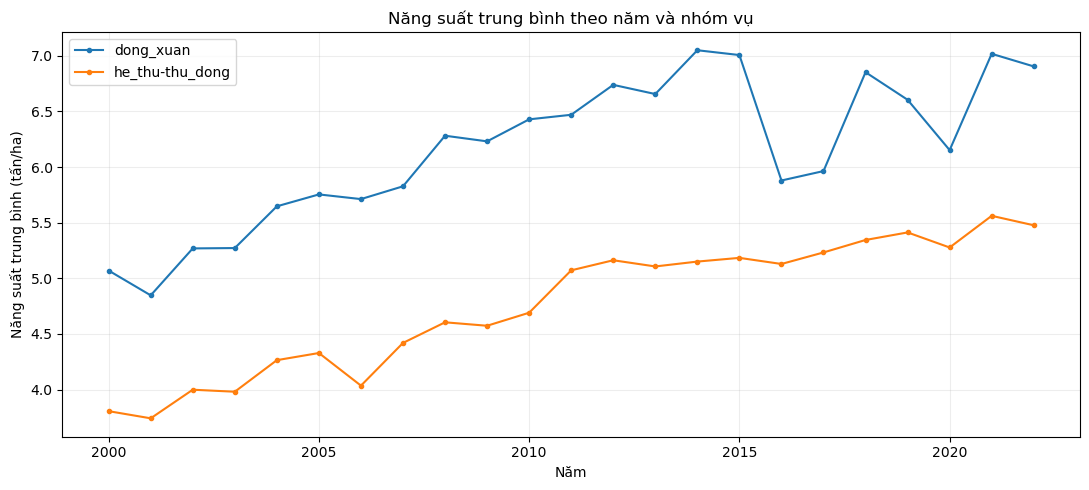

In [5]:
fig, ax = plt.subplots()
ax.hist(df[TARGET], bins=25, edgecolor='white')
ax.axvline(df[TARGET].median(), linestyle='--', label=f'Trung vị = {df[TARGET].median():.2f}')
ax.set(title='Phân phối năng suất lúa (2000–2022)', xlabel='Năng suất (tấn/ha)', ylabel='Số bản ghi')
ax.legend(); plt.tight_layout(); save_fig('02_phan_phoi_nang_suat.png'); plt.show()

fig, ax = plt.subplots()
seasons = sorted(df['mua_vu'].unique())
ax.boxplot([df.loc[df['mua_vu'] == s, TARGET] for s in seasons], tick_labels=seasons)
ax.set(title='Năng suất theo nhóm vụ', ylabel='Năng suất (tấn/ha)')
ax.tick_params(axis='x', labelrotation=10)
plt.tight_layout(); save_fig('03_nang_suat_theo_nhom_vu.png'); plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
yearly = df.groupby(['nam', 'mua_vu'])[TARGET].mean().unstack()
for season in yearly.columns:
    ax.plot(yearly.index, yearly[season], marker='o', markersize=3, label=season)
ax.set(title='Năng suất trung bình theo năm và nhóm vụ', xlabel='Năm', ylabel='Năng suất trung bình (tấn/ha)')
ax.legend(); plt.tight_layout(); save_fig('04_xu_huong_nang_suat.png'); plt.show()

## Import CSV và chia tập dữ liệu theo năm
- Train: năm 2000–2015; dữ liệu dùng để học mô hình và để tính tương quan phục vụ phân tích đầu vào.
- Validation: 2016–2018; chọn mô hình tốt nhất theo MAE.
- Test: 2019–2022; chỉ đánh giá sau khi đã chọn mô hình.

Không xáo trộn ngẫu nhiên toàn bộ 579 dòng, tránh đưa quan sát từ tương lai vào quá trình học của giai đoạn trước.

In [6]:
train_df = df.loc[df['nam'].between(2000, 2015)].copy().reset_index(drop=True)
val_df = df.loc[df['nam'].between(2016, 2018)].copy().reset_index(drop=True)
test_df = df.loc[df['nam'].between(2019, 2022)].copy().reset_index(drop=True)
trainval_df = pd.concat([train_df, val_df], ignore_index=True)
assert (len(train_df), len(val_df), len(test_df)) == (399, 76, 104)
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_val, y_val = val_df[FEATURES], val_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]
X_trainval, y_trainval = trainval_df[FEATURES], trainval_df[TARGET]
print('Train:', len(train_df), '| Validation:', len(val_df), '| Test:', len(test_df))
display(pd.DataFrame([
    {'Tập':'Train','Năm':'2000–2015','Bản ghi':len(train_df)},
    {'Tập':'Validation','Năm':'2016–2018','Bản ghi':len(val_df)},
    {'Tập':'Test','Năm':'2019–2022','Bản ghi':len(test_df)},
]))

Train: 399 | Validation: 76 | Test: 104


,Tập,Năm,Bản ghi
0,Train,2000–2015,399
1,Validation,2016–2018,76
2,Test,2019–2022,104


## Ma trận tương quan và độ tương quan với nhãn

Chỉ tính tương quan trên Train để không dựa vào nhãn của Validation/Test khi diễn giải hoặc lựa chọn thuộc tính. Pearson mô tả quan hệ tuyến tính; Spearman mô tả quan hệ đơn điệu. Cả hai không suy ra quan hệ nhân quả. Các thuộc tính đồng biến theo năm có thể phản ánh xu thế chung.

MỨC ĐỘ TƯƠNG QUAN VỚI NHÃN (Train 2000–2015):


,pearson_r,spearman_rho,abs_pearson
rainfall_sum_mm,-0.647,-0.604,0.647
rainy_months_100mm,-0.623,-0.555,0.623
rainfall_max_month_mm,-0.554,-0.577,0.554
vi_months_available,-0.537,-0.636,0.537
nam,0.489,0.487,0.489
evi_max,0.456,0.450,0.456
evi_mean,0.437,0.479,0.437
vi_months_quality80,-0.421,-0.533,0.421
temperature_min_c,-0.376,-0.368,0.376
vci_mean,0.302,0.342,0.302


Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\05_ma_tran_tuong_quan.png


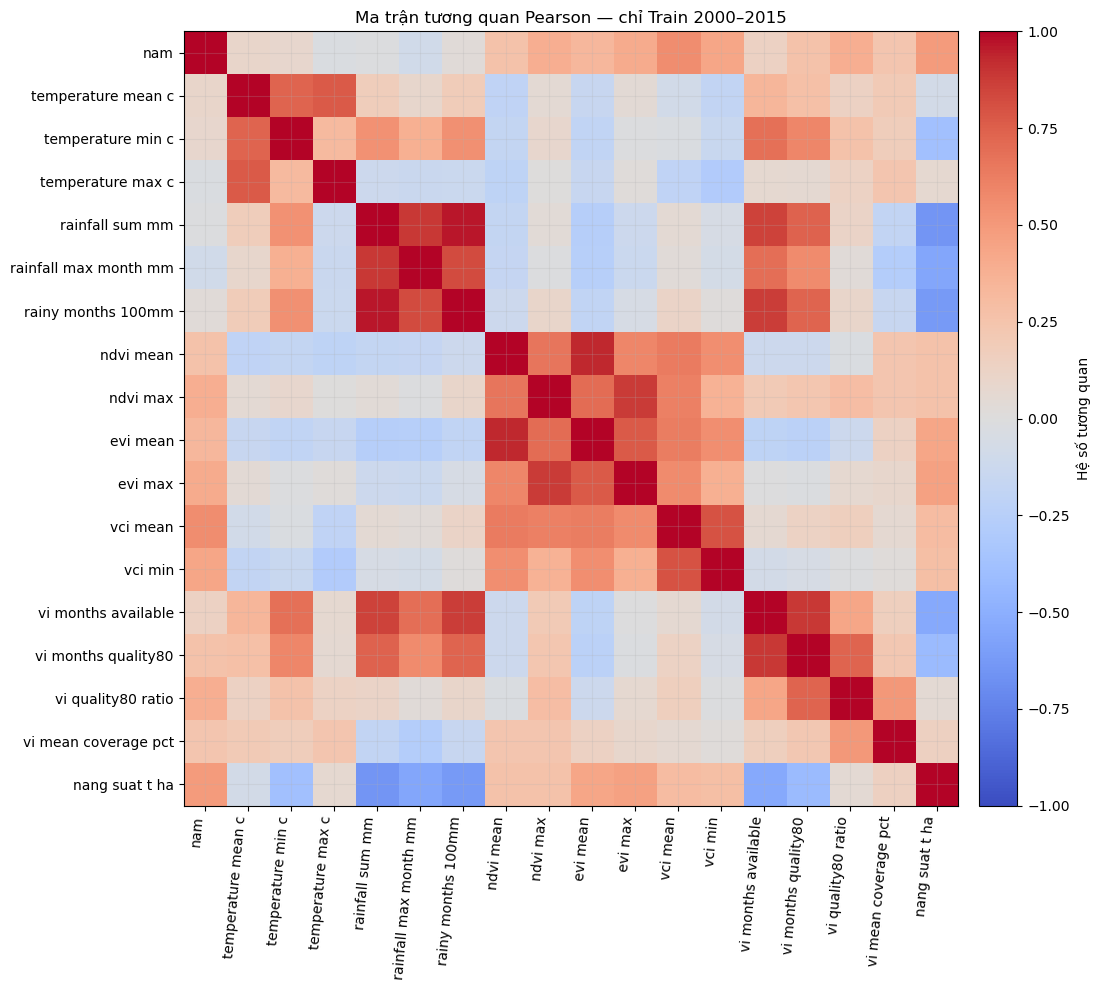

Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\06_tuong_quan_voi_nhan.png


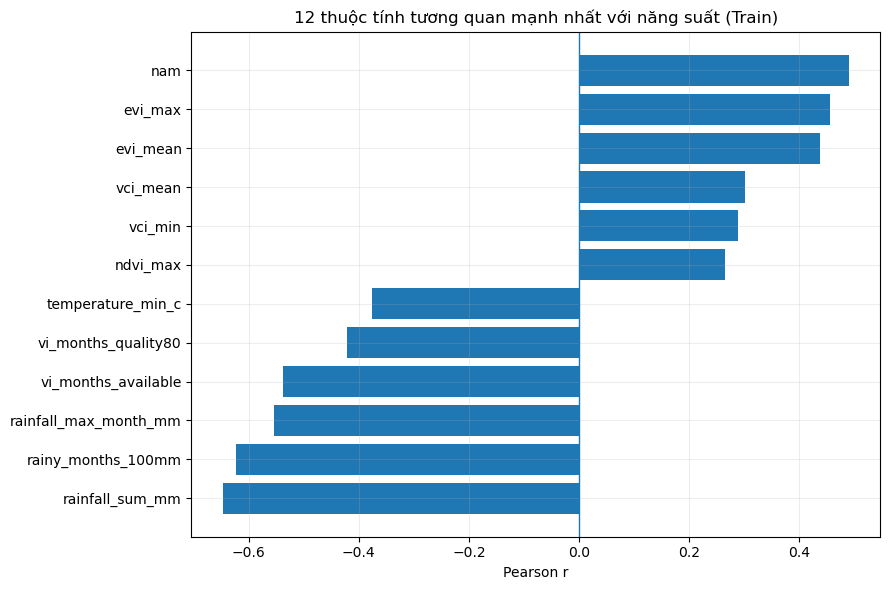

In [7]:
corr_features = NUMERIC_FEATURES + [TARGET]
pearson_matrix = train_df[corr_features].corr(method='pearson')
pearson_target = pearson_matrix[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False)
spearman_target = train_df[corr_features].corr(method='spearman')[TARGET].drop(TARGET)

corr_table = pd.DataFrame({
    'pearson_r': pearson_target,
    'spearman_rho': spearman_target.reindex(pearson_target.index),
    'abs_pearson': pearson_target.abs(),
}).round(3)
print('MỨC ĐỘ TƯƠNG QUAN VỚI NHÃN (Train 2000–2015):')
display(corr_table)

fig, ax = plt.subplots(figsize=(12, 10))
mat = ax.imshow(pearson_matrix, vmin=-1, vmax=1, cmap='coolwarm')
labels = [c.replace('_', ' ') for c in corr_features]
ax.set_xticks(range(len(labels)), labels=labels, rotation=85, ha='right')
ax.set_yticks(range(len(labels)), labels=labels)
ax.set_title('Ma trận tương quan Pearson — chỉ Train 2000–2015')
fig.colorbar(mat, ax=ax, fraction=0.04, pad=0.02, label='Hệ số tương quan')
plt.tight_layout(); save_fig('05_ma_tran_tuong_quan.png'); plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
top = pearson_target.head(12).sort_values()
ax.barh(top.index, top.values)
ax.axvline(0, linewidth=1)
ax.set(xlabel='Pearson r', title='12 thuộc tính tương quan mạnh nhất với năng suất (Train)')
plt.tight_layout(); save_fig('06_tuong_quan_voi_nhan.png'); plt.show()

## Biểu đồ phân tán của các đặc trưng liên quan đến năng suất

Chọn 4 thuộc tính có |Pearson| lớn nhất trên tập Train. Đường thẳng chỉ là xu hướng tuyến tính, không chứng minh ảnh hưởng nhân quả.

Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\07_scatter_1_rainfall_sum_mm.png


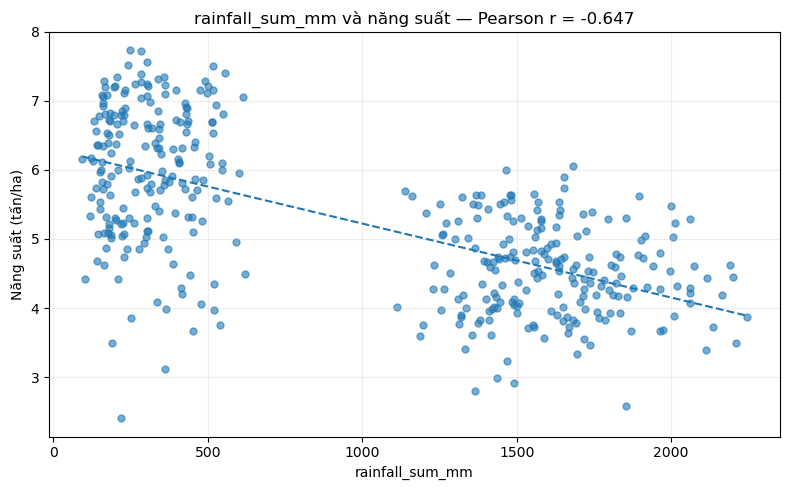

Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\07_scatter_2_rainy_months_100mm.png


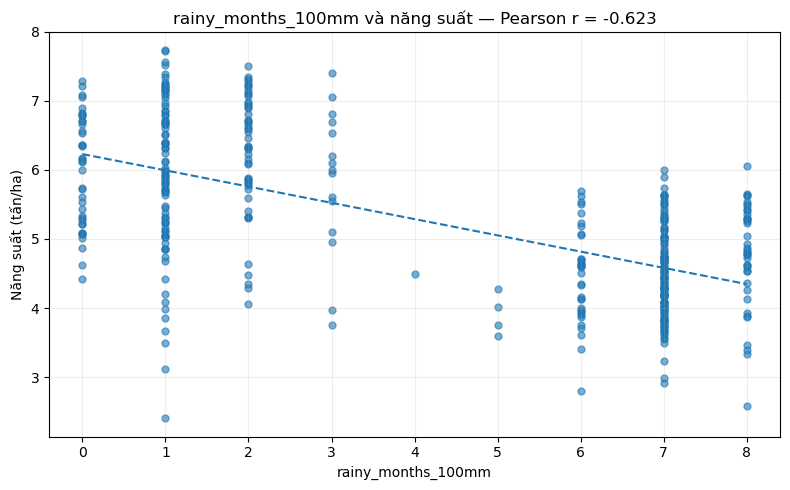

Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\07_scatter_3_rainfall_max_month_mm.png


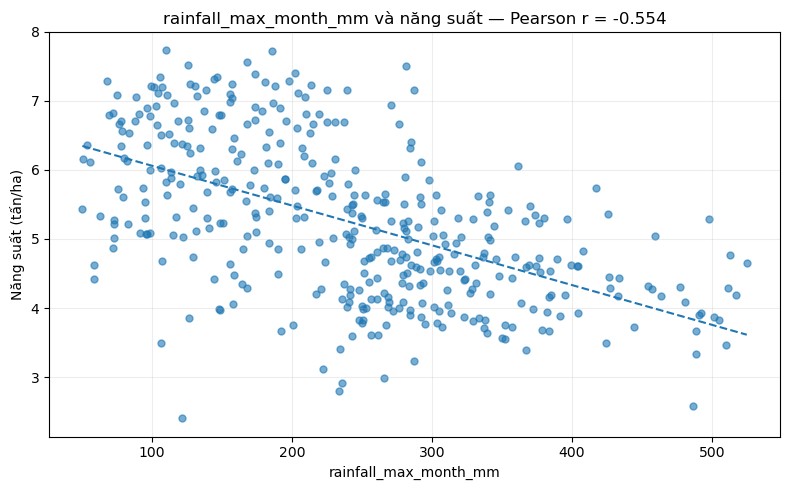

Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\07_scatter_4_vi_months_available.png


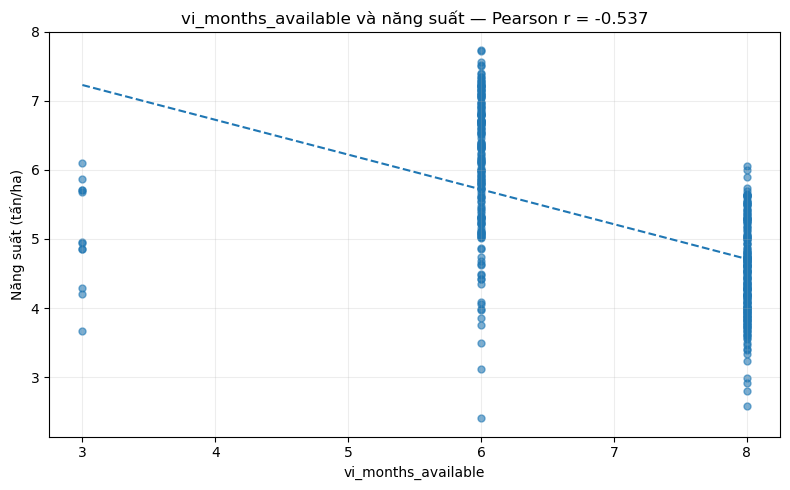

In [8]:
top4 = pearson_target.head(4).index.tolist()
for j, col in enumerate(top4, start=1):
    temp = train_df[[col, TARGET]].dropna()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(temp[col], temp[TARGET], alpha=0.6, s=25)
    if temp[col].nunique() > 1:
        m, b = np.polyfit(temp[col], temp[TARGET], 1)
        xx = np.linspace(temp[col].min(), temp[col].max(), 100)
        ax.plot(xx, m * xx + b, linestyle='--')
    ax.set(xlabel=col, ylabel='Năng suất (tấn/ha)',
           title=f'{col} và năng suất — Pearson r = {pearson_target[col]:.3f}')
    plt.tight_layout(); save_fig(f'07_scatter_{j}_{col}.png'); plt.show()

## Khởi tạo 7 mô hình cơ sở và quy trình tiền xử lý

In [10]:
def make_preprocessor():
    num = Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scale', StandardScaler()),
    ])
    cat = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    return ColumnTransformer([
        ('numeric', num, NUMERIC_FEATURES),
        ('categorical', cat, CATEGORICAL_FEATURES),
    ], sparse_threshold=0)

def model_pipeline(regressor):
    return Pipeline([
        ('prep', make_preprocessor()),
        ('regressor', regressor),
    ])

base_models = {
    'Dummy': model_pipeline(DummyRegressor(strategy='mean')),
    'Ridge': model_pipeline(Ridge(alpha=10.0)),
    'ElasticNet': model_pipeline(ElasticNet(alpha=0.1, l1_ratio=0.4, max_iter=8000, random_state=RANDOM_STATE)),
    'SVR': model_pipeline(SVR(kernel='rbf', C=5.0, epsilon=0.15)),
    'RandomForest': model_pipeline(RandomForestRegressor(
        n_estimators=150, min_samples_leaf=3, max_features=0.85,
        random_state=RANDOM_STATE, n_jobs=-1)),
    'ExtraTrees': model_pipeline(ExtraTreesRegressor(
        n_estimators=150, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1)),
    'HistGradientBoosting': model_pipeline(HistGradientBoostingRegressor(
        max_iter=120, max_leaf_nodes=10, learning_rate=0.05,
        l2_regularization=3.0, random_state=RANDOM_STATE)),
}
STACK_BASE = ['Ridge', 'SVR', 'RandomForest', 'ExtraTrees', 'HistGradientBoosting']

def evaluate(y_true, pred):
    return {
        'MAE_t_ha': mean_absolute_error(y_true, pred),
        'RMSE_t_ha': float(np.sqrt(mean_squared_error(y_true, pred))),
        'R2': r2_score(y_true, pred),
    }
print('Các mô hình cơ sở:', ', '.join(base_models))
print('Các mô hình thành phần của Stacking:', ', '.join(STACK_BASE))

Các mô hình cơ sở: Dummy, Ridge, ElasticNet, SVR, RandomForest, ExtraTrees, HistGradientBoosting
Các mô hình thành phần của Stacking: Ridge, SVR, RandomForest, ExtraTrees, HistGradientBoosting


## Huấn luyện mô hình cơ sở trên Train, đánh giá Validation

In [11]:
trained_on_train = {}
val_predictions = {}
for name, template in base_models.items():
    estimator = clone(template)
    estimator.fit(X_train, y_train)
    trained_on_train[name] = estimator
    val_predictions[name] = estimator.predict(X_val)

base_val_metrics = pd.DataFrame([
    {'model': name, **evaluate(y_val, pred)}
    for name, pred in val_predictions.items()
]).sort_values('MAE_t_ha').reset_index(drop=True)
print('KẾT QUẢ VALIDATION — CÁC MÔ HÌNH CƠ SỞ:')
display(base_val_metrics.round(4))

c:\Users\ascha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\ascha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\ascha\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ascha\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

KẾT QUẢ VALIDATION — CÁC MÔ HÌNH CƠ SỞ:


,model,MAE_t_ha,RMSE_t_ha,R2
0,ExtraTrees,0.4981,0.8660,0.4354
1,HistGradientBoosting,0.5131,0.9399,0.3349
2,RandomForest,0.5220,0.9667,0.2964
3,SVR,0.5778,0.9530,0.3161
4,Ridge,0.6096,1.0159,0.2229
5,ElasticNet,0.6183,1.0818,0.1189
6,Dummy,0.9552,1.2439,-0.1650


## Tạo dự đoán OOF theo thời gian để huấn luyện Stacking

Quan trọng: Không huấn luyện meta-model trên dự đoán Validation rồi dùng chính Validation để xếp hạng nó. Thay vào đó, ta lấy dự đoán ngoài mẫu theo các chặng năm bên trong Train:
- Học đến 2007 → dự đoán 2008–2010.
- Học đến 2010 → dự đoán 2011–2013.
- Học đến 2013 → dự đoán 2014–2015.
- Khi huấn luyện lại trên Train+Validation, thêm chặng học đến 2015 → dự đoán 2016–2018.

In [19]:
FOLDS = [
    (2007, 2008, 2010),
    (2010, 2011, 2013),
    (2013, 2014, 2015),
    (2015, 2016, 2018),
]

def make_temporal_oof(history_df):
    fold_frames = []
    fold_report = []
    for train_end, pred_start, pred_end in FOLDS:
        fit_part = history_df.loc[history_df['nam'] <= train_end]
        pred_part = history_df.loc[history_df['nam'].between(pred_start, pred_end)]
        if pred_part.empty:
            continue
        if fit_part.empty:
            raise ValueError('Tập huấn luyện OOF trống.')
        fold_preds = {}
        for name in STACK_BASE:
            estimator = clone(base_models[name])
            estimator.fit(fit_part[FEATURES], fit_part[TARGET])
            fold_preds[name] = estimator.predict(pred_part[FEATURES])
        temp = pd.DataFrame(fold_preds, index=pred_part.index)
        temp['actual'] = pred_part[TARGET].to_numpy()
        temp['year'] = pred_part['nam'].to_numpy()
        fold_frames.append(temp)
        fold_report.append({
            'fit_until': train_end,
            'predict_years': f'{pred_start}–{pred_end}',
            'fit_rows': len(fit_part),
            'oof_rows': len(pred_part),
        })
    if not fold_frames:
        raise ValueError('Không tạo được dự đoán OOF.')
    return pd.concat(fold_frames, ignore_index=True), pd.DataFrame(fold_report)

oof_train, fold_summary = make_temporal_oof(train_df)
meta_on_train = Ridge(alpha=3.0)
meta_on_train.fit(oof_train[STACK_BASE], oof_train['actual'])
stack_val_input = pd.DataFrame({name: val_predictions[name] for name in STACK_BASE})
val_predictions['Stacking'] = meta_on_train.predict(stack_val_input)
print('Các fold OOF của Train:')
display(fold_summary)
print('Số dự đoán OOF dùng học meta-model:', len(oof_train))

Các fold OOF của Train:


,fit_until,predict_years,fit_rows,oof_rows
0,2007,2008–2010,199,75
1,2010,2011–2013,274,75
2,2013,2014–2015,349,50


Số dự đoán OOF dùng học meta-model: 200


## So sánh tất cả mô hình trên Validation và chọn mô hình tốt nhất

Quy tắc chọn trước: MAE nhỏ nhất; nếu bằng nhau thì RMSE nhỏ nhất. Tập Test vẫn chưa được sử dụng. Stacking được đối chiếu công bằng vì meta-model chỉ học từ OOF trong Train.

BẢNG SO SÁNH VALIDATION (MAE thấp nhất xếp đầu):


,model,split,MAE_t_ha,RMSE_t_ha,R2
0,ExtraTrees,validation_2016_2018,0.4981,0.8660,0.4354
1,HistGradientBoosting,validation_2016_2018,0.5131,0.9399,0.3349
2,RandomForest,validation_2016_2018,0.5220,0.9667,0.2964
3,SVR,validation_2016_2018,0.5778,0.9530,0.3161
4,Ridge,validation_2016_2018,0.6096,1.0159,0.2229
5,ElasticNet,validation_2016_2018,0.6183,1.0818,0.1189
6,Stacking,validation_2016_2018,0.7129,1.0522,0.1664
7,Dummy,validation_2016_2018,0.9552,1.2439,-0.1650



MÔ HÌNH ĐƯỢC CHỌN TRÊN VALIDATION: ExtraTrees
Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\08_mae_validation.png


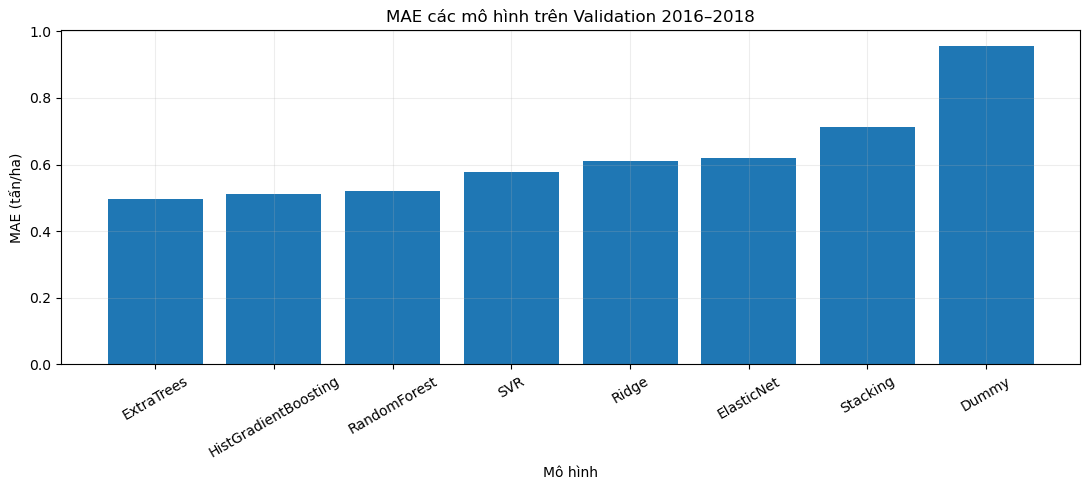

In [20]:
validation_metrics = pd.DataFrame([
    {'model': name, 'split': 'validation_2016_2018', **evaluate(y_val, pred)}
    for name, pred in val_predictions.items()
]).sort_values(['MAE_t_ha', 'RMSE_t_ha']).reset_index(drop=True)
BEST_NAME = validation_metrics.loc[0, 'model']
print('BẢNG SO SÁNH VALIDATION (MAE thấp nhất xếp đầu):')
display(validation_metrics.round(4))
print(f'\nMÔ HÌNH ĐƯỢC CHỌN TRÊN VALIDATION: {BEST_NAME}')

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(validation_metrics['model'], validation_metrics['MAE_t_ha'])
ax.set(title='MAE các mô hình trên Validation 2016–2018', xlabel='Mô hình', ylabel='MAE (tấn/ha)')
ax.tick_params(axis='x', labelrotation=30)
plt.tight_layout(); save_fig('08_mae_validation.png'); plt.show()

## Mức độ quan trọng bằng hoán vị trên Validation (bổ sung cho tương quan)

Đo mức tăng MAE khi đảo ngẫu nhiên từng đặc trưng Validation, giữ mô hình đã học cố định (3 lần lặp). Chỉ số này phản ánh độ nhạy của mô hình, không chứng minh tác động nhân quả; có thể bị ảnh hưởng bởi tính tương quan giữa các biến.

,feature,delta_MAE_t_ha
0,adm1_code,0.2358
1,mua_vu,0.2286
11,evi_mean,0.0231
13,vci_mean,0.0102
3,temperature_mean_c,0.0036
10,ndvi_max,0.0026
14,vci_min,0.0020
12,evi_max,0.0018
9,ndvi_mean,0.0017
16,vi_months_quality80,0.0010


Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\09_do_nhay_dac_trung_validation.png


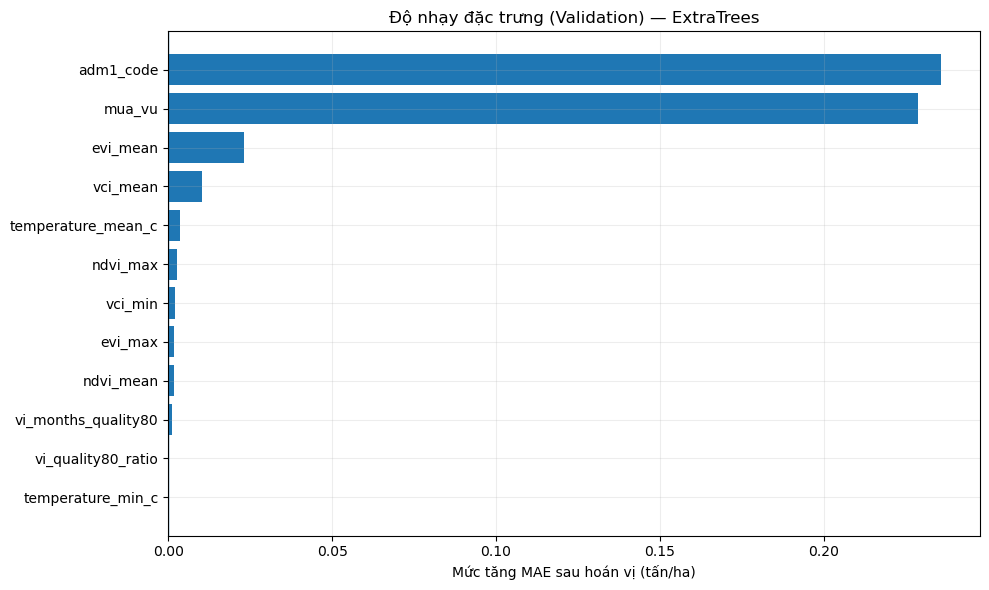

In [21]:
def predict_with_selected_val(frame):
    if BEST_NAME == 'Stacking':
        meta_X = pd.DataFrame({
            name: trained_on_train[name].predict(frame)
            for name in STACK_BASE
        })
        return meta_on_train.predict(meta_X)
    return trained_on_train[BEST_NAME].predict(frame)

rng = np.random.default_rng(RANDOM_STATE)
baseline_val_mae = mean_absolute_error(y_val, predict_with_selected_val(X_val))
importance_rows = []
for feat in FEATURES:
    deltas = []
    for _ in range(3):
        changed = X_val.copy()
        changed[feat] = rng.permutation(changed[feat].to_numpy())
        deltas.append(mean_absolute_error(y_val, predict_with_selected_val(changed)) - baseline_val_mae)
    importance_rows.append({'feature': feat, 'delta_MAE_t_ha': float(np.mean(deltas))})
importance_df = pd.DataFrame(importance_rows).sort_values('delta_MAE_t_ha', ascending=False)
display(importance_df.round(4))
fig, ax = plt.subplots(figsize=(10, 6))
imp_top = importance_df.head(12).sort_values('delta_MAE_t_ha')
ax.barh(imp_top['feature'], imp_top['delta_MAE_t_ha'])
ax.axvline(0, linewidth=1)
ax.set(title=f'Độ nhạy đặc trưng (Validation) — {BEST_NAME}', xlabel='Mức tăng MAE sau hoán vị (tấn/ha)')
plt.tight_layout(); save_fig('09_do_nhay_dac_trung_validation.png'); plt.show()

## Huấn luyện lại trên Train+Validation và đánh giá Test một lần

Sau khi đã chốt BEST_NAME, huấn luyện lại toàn bộ mô hình cơ sở trên 2000–2018. Meta-model Stacking cũng được học lại từ OOF chỉ đến 2018. Test 2019–2022 được dùng để đánh giá cuối cùng, không được dùng để đổi tên mô hình thắng cuộc hoặc tinh chỉnh siêu tham số.

In [22]:
trained_final = {}
test_predictions = {}
for name, template in base_models.items():
    estimator = clone(template)
    estimator.fit(X_trainval, y_trainval)
    trained_final[name] = estimator
    test_predictions[name] = estimator.predict(X_test)

oof_trainval, fold_trainval = make_temporal_oof(trainval_df)
meta_final = Ridge(alpha=3.0)
meta_final.fit(oof_trainval[STACK_BASE], oof_trainval['actual'])
stack_test_input = pd.DataFrame({name: test_predictions[name] for name in STACK_BASE})
test_predictions['Stacking'] = meta_final.predict(stack_test_input)

test_metrics = pd.DataFrame([
    {'model': name, 'split': 'test_2019_2022', **evaluate(y_test, pred)}
    for name, pred in test_predictions.items()
]).sort_values(['MAE_t_ha', 'RMSE_t_ha']).reset_index(drop=True)
metrics_all = pd.concat([validation_metrics, test_metrics], ignore_index=True)

print('Mô hình đã được chọn từ Validation:', BEST_NAME)
print('KẾT QUẢ TEST — CHỈ ĐÁNH GIÁ:')
display(test_metrics.round(4))
selected_test = test_metrics.loc[test_metrics['model'] == BEST_NAME].iloc[0]
print(f"MAE mô hình đã chọn: {selected_test['MAE_t_ha']:.4f} tấn/ha")
print(f"RMSE: {selected_test['RMSE_t_ha']:.4f} tấn/ha | R²: {selected_test['R2']:.4f}")

Mô hình đã được chọn từ Validation: ExtraTrees
KẾT QUẢ TEST — CHỈ ĐÁNH GIÁ:


,model,split,MAE_t_ha,RMSE_t_ha,R2
0,Ridge,test_2019_2022,0.3750,0.7185,0.6095
1,Stacking,test_2019_2022,0.4597,0.7744,0.5463
2,ExtraTrees,test_2019_2022,0.5043,0.7591,0.5640
3,ElasticNet,test_2019_2022,0.5165,0.8693,0.4283
4,SVR,test_2019_2022,0.5358,0.7897,0.5282
5,HistGradientBoosting,test_2019_2022,0.5369,0.7684,0.5533
6,RandomForest,test_2019_2022,0.5462,0.7765,0.5439
7,Dummy,test_2019_2022,1.0715,1.3604,-0.4002


MAE mô hình đã chọn: 0.5043 tấn/ha
RMSE: 0.7591 tấn/ha | R²: 0.5640


## 

Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\10_test_mae_t_ha.png


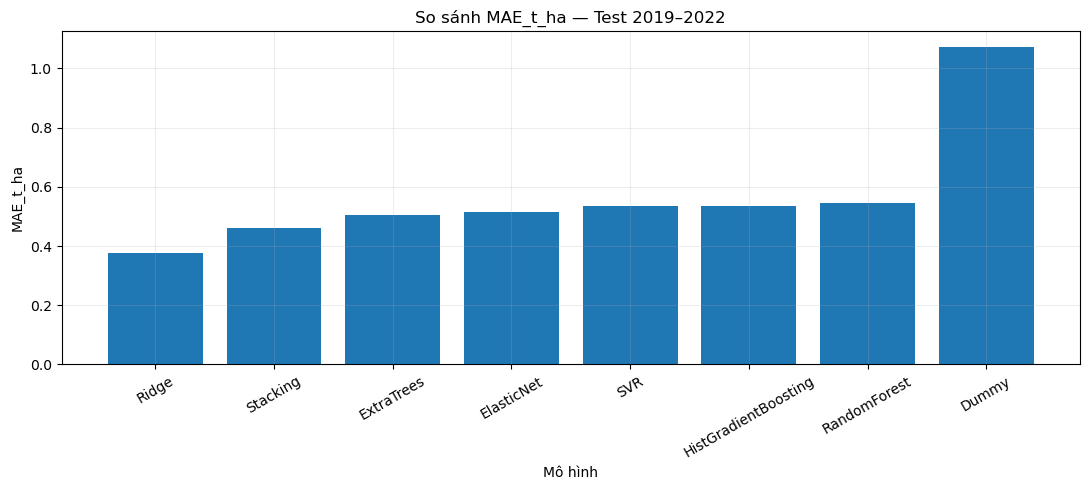

Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\10_test_rmse_t_ha.png


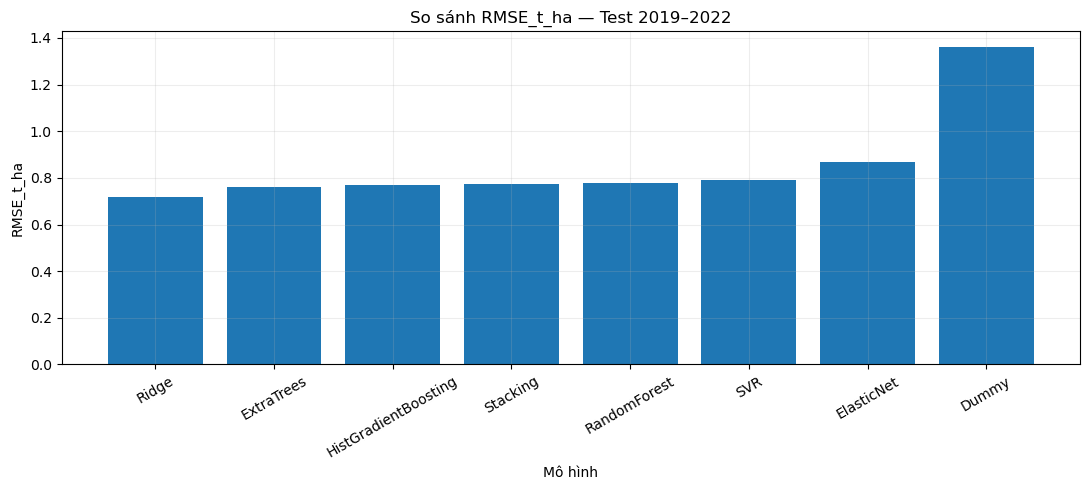

Đã lưu: C:\Users\ascha\Documents\=TAI LIEU DAI HOC CAN THO=\Nam4\HK1\NLNKHMT\rice_yield_estimation\reports\figures\10_test_r2.png


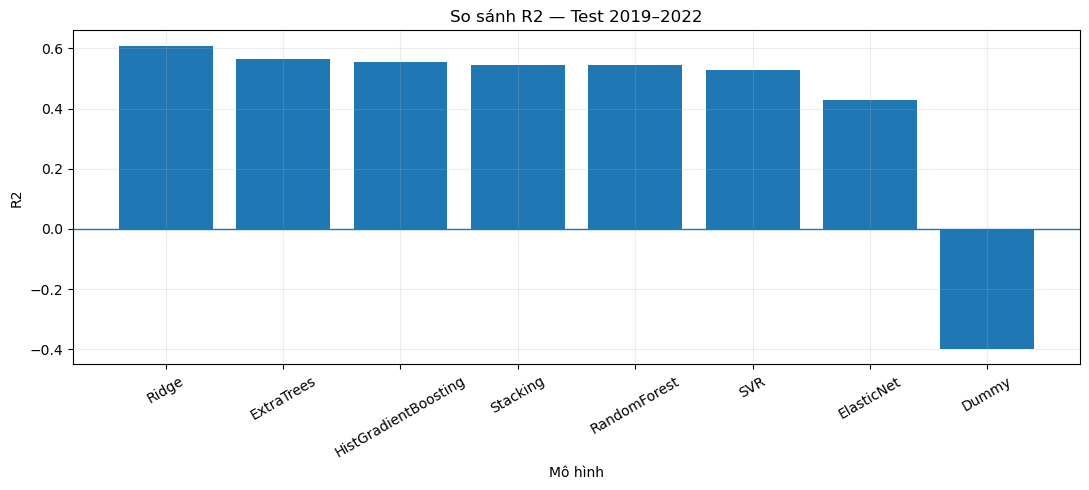

In [23]:
plot_metrics = ['MAE_t_ha', 'RMSE_t_ha', 'R2']
for metric in plot_metrics:
    d = test_metrics.sort_values(metric, ascending=(metric != 'R2'))
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(d['model'], d[metric])
    ax.set(title=f'So sánh {metric} — Test 2019–2022', xlabel='Mô hình', ylabel=metric)
    ax.tick_params(axis='x', labelrotation=30)
    if metric == 'R2':
        ax.axhline(0, linewidth=1)
    plt.tight_layout()
    save_fig('10_test_' + metric.lower() + '.png')
    plt.show()

## Xuất báo cáo CSV và lưu mô hình

In [ ]:
metrics_path = REPORTS / 'rice_model_metrics.csv'
with metrics_path.open('w', encoding='utf-8-sig', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=list(metric_rows[0]))
    writer.writeheader()
    writer.writerows(metric_rows)

prediction_path = REPORTS / 'rice_test_predictions.csv'
fieldnames = [
    'adm1_code', 'tinh_thanh', 'nam', 'mua_vu',
    'actual_t_ha', 'predicted_t_ha', 'abs_error_t_ha',
]
with prediction_path.open('w', encoding='utf-8-sig', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    test_rows = [row for row, is_test in zip(rows, test) if is_test]
    for row, prediction, actual in zip(test_rows, stacked, y[test]):
        writer.writerow({
            'adm1_code': row['adm1_code'],
            'tinh_thanh': row['tinh_thanh'],
            'nam': row['nam'],
            'mua_vu': row['mua_vu'],
            'actual_t_ha': round(float(actual), 6),
            'predicted_t_ha': round(float(prediction), 6),
            'abs_error_t_ha': round(abs(float(prediction) - float(actual)), 6),
        })

model_path = MODELS / 'rice_stacking_model.joblib'
joblib.dump({
    'base_models': models,
    'meta_model': stacker,
    'feature_names': FEATURES,
    'train_period': '2000-2018',
    'test_period': '2019-2022',
    'window_policy': 'dong_xuan=Nov-Apr; he_thu-thu_dong=Apr-Nov (proxy)',
    'satellite_mask': 'rice_map_2020',
}, model_path)

print('=== LƯU KẾT QUẢ ===')
print('Bảng chỉ số:', metrics_path)
print('Dự đoán Test:', prediction_path)
print('Mô hình:', model_path)